# 09 — Optuna: attention heads and feedforward width
Run notebook 08's search first. This notebook reuses its selected learning rate, weight decay, dropout and narration sampling weight. It reuses the same cached features, labels, split and class weights. It does not rerun feature extraction when samples.pt exists.

**Search:** all 9 combinations of `num_heads = [2, 4, 8]` and `dim_feedforward = [256, 512, 1024]`. The latter is the hidden dimension inside each Transformer feedforward block; `d_model` stays 256, with two layers. Each head therefore has 128, 64 or 32 dimensions. Every candidate trains seeds 42, 123 and 2026; the objective is mean best-checkpoint validation macro F1. The original architecture (4 heads, feedforward 512) is queued first. No pruning.

Run cells in order. The selected architecture is then reported across five seeds, and the final cell plots saved trial history and parameter importance. Results live separately in `runs/optuna_architecture/`. Nine trials mean 27 training runs plus two additional report seeds. Repeated tuning uses development validation data; these scores are not an independent test estimate.

The separate helpers preserve notebooks 07/08 and their resume fingerprints. For inference, instantiate `model_architecture.BoxClassifier` with checkpoint `num_heads`, `dim_feedforward`, `dropout`, `visual_dim` and `max_positions`, then load `state_dict`.


**Padded-box experiment:** retains original DETR features and adds frozen local DINOv2 crop features. Uses this folder's caches, split snapshot, studies and checkpoints.


In [1]:
# Reuse missing base caches in this isolated experiment before checking prerequisites.
from config import reuse_base_caches
reuse_base_caches()

# Cell purpose: Reuse cached samples and notebook 08's best settings; configure the architecture search.
# Inputs: samples.pt and notebook 08's saved study or best_parameters.json.
# Outputs: Fixed split, fixed optimization settings and nine candidate architectures. No training yet.
from pathlib import Path
import json
import hashlib
import numpy as np
import pandas as pd
import torch
from IPython.display import display
from config import CONFIG, fingerprint, save_json, require_cache
from training_architecture_runs import train_one_seed, summarize_runs, split_manifest, validate_split
try:
    import optuna
except ImportError as error:
    raise ImportError('Run %pip install "optuna>=4,<6" in this kernel first.') from error

CACHE = CONFIG['cache_dir']
RUN = CONFIG['run_dir']
require_cache(CACHE / 'samples.pt', '04_build_training_samples.ipynb')
# Refresh stale padded features before reusing samples/checkpoints.
from config import run_stage
run_stage('04_build_training_samples.ipynb')
data = torch.load(CACHE / 'samples.pt', map_location='cpu', weights_only=True)
validate_split(data)
SPLIT = split_manifest(data)

# CONFIG: Change these paths only if notebook 08 used a different output/study name.
PREVIOUS_OUTPUT = RUN / 'optuna_tuning'
PREVIOUS_STUDY_NAME = 'fixed_split_macro_f1_v1'
previous_manifest = json.loads((PREVIOUS_OUTPUT / 'manifest.json').read_text(encoding='utf-8'))
assert previous_manifest['split'] == SPLIT, 'Notebook 08 used another split/cache.'
selected_file = PREVIOUS_OUTPUT / 'best_parameters.json'
if selected_file.exists():
    selected = json.loads(selected_file.read_text(encoding='utf-8'))
    assert selected['split'] == SPLIT
    BASE_PARAMS = dict(selected['params'])
else:
    # A finished search is enough; notebook 08's five-seed report need not be completed.
    previous_database = PREVIOUS_OUTPUT / 'study.db'
    assert previous_database.exists(), 'Run notebook 08 search first.'
    previous_study = optuna.load_study(study_name=PREVIOUS_STUDY_NAME,
        storage='sqlite:///' + previous_database.resolve().as_posix())
    assert previous_study.user_attrs['experiment_id'] == fingerprint(previous_manifest)
    BASE_PARAMS = dict(previous_manifest['base_params'])
    BASE_PARAMS.update(previous_study.best_params)

# Keep d_model=256, two layers and all non-architecture settings fixed.
BASE_PARAMS.update(num_heads=4, dim_feedforward=512)
SEARCH_SPACE = {'num_heads': [2, 4, 8, 16, 32], 'dim_feedforward': [256, 512, 1024, 2048]}
SEARCH_SEEDS = [42, 123, 2026]
REPORT_SEEDS = [42, 123, 2026, 7, 99]
TOTAL_TRIALS = 9
STUDY_NAME = 'fixed_split_architecture_v1'
OUTPUT = RUN / 'optuna_architecture'
assert all(256 % heads == 0 for heads in SEARCH_SPACE['num_heads'])
print('Fixed split:', len(SPLIT['train_sequences']), 'train /', len(SPLIT['val_sequences']), 'validation')
print('Settings:', BASE_PARAMS)
print('Architecture search:', SEARCH_SPACE)


Running prerequisite: 04_build_training_samples.ipynb
Running prerequisite: 03a_cache_dino_crops.ipynb
Local encoder: C:\MODELS\dinov2-small
Padding per side: 0.2 | matching feature cache: True
DINO features: C:\Users\ESHAAN\BYTE\Applied-Task\Magi\FINETUNING-EXPERMENTS\NarrationImbalanceTrainingPaddedBox\cache\dino.pt | sequences: 80
Reuse matching padded samples: True
Exact original split: 64 train / 16 validation
Original train class counts: [1142, 50]
Feature widths: text 768, DETR 256, DINO 384, geometry 4, tail 2; fused input 688.
Saved: C:\Users\ESHAAN\BYTE\Applied-Task\Magi\FINETUNING-EXPERMENTS\NarrationImbalanceTrainingPaddedBox\cache\samples.pt
Fixed split: 64 train / 16 validation
Settings: {'lr': 0.0007773311543779756, 'weight_decay': 0.0005696795742896767, 'dropout': 0.1, 'batch_size': 4, 'epochs': 20, 'narration_sampling_weight': 2.0, 'num_heads': 4, 'dim_feedforward': 512}
Architecture search: {'num_heads': [2, 4, 8, 16, 32], 'dim_feedforward': [256, 512, 1024, 2048]}


Create or resume a persistent study after checking data, code and search-setting identity.


In [2]:
# Cell purpose: Create or resume a persistent study after checking data, code and search-setting identity.
# Inputs: The frozen experiment manifest and the study SQLite file, if present.
# Outputs: A seeded exhaustive grid study with no pruning and the baseline queued first.

OUTPUT.mkdir(parents=True, exist_ok=True)
# Reject study reuse after the model or shared training loop has changed.
code_hashes = {name: hashlib.sha256(Path(name).read_bytes()).hexdigest()
               for name in ['model_architecture.py', 'training_architecture_runs.py']}
# Record the exact experiment identity and reject incompatible results on a later rerun.
manifest = {'split': SPLIT, 'base_params': BASE_PARAMS, 'search_seeds': SEARCH_SEEDS,
            'report_seeds': REPORT_SEEDS, 'search_space': SEARCH_SPACE, 'code': code_hashes,
            'objective': 'mean_macro_f1', 'selection': 'macro_f1'}
manifest_file = OUTPUT / 'manifest.json'
if manifest_file.exists():
    assert json.loads(manifest_file.read_text(encoding='utf-8')) == manifest, 'Study settings changed; choose a new OUTPUT folder.'
save_json(manifest_file, manifest)

# Persist study trials in a local SQLite database so completed optimization work survives notebook restarts.
storage = 'sqlite:///' + (OUTPUT / 'study.db').resolve().as_posix()
# Maximize mean macro F1 using seeded exhaustive grid; pruning is intentionally disabled.
study = optuna.create_study(study_name=STUDY_NAME, storage=storage, direction='maximize',
    sampler=optuna.samplers.GridSampler(SEARCH_SPACE, seed=42),
    pruner=optuna.pruners.NopPruner(), load_if_exists=True)
study_id = fingerprint(manifest)
if study.user_attrs.get('experiment_id') is not None:
    assert study.user_attrs['experiment_id'] == study_id, 'Study belongs to another dataset/settings.'
study.set_user_attr('experiment_id', study_id)
# Queue the original configuration once, making it the first trial of a new study.
if not study.trials:
    study.enqueue_trial({key: BASE_PARAMS[key] for key in SEARCH_SPACE})
print('Stored trials:', len(study.trials), '| database:', OUTPUT / 'study.db')

[I 2026-10-10 06:02:51,277] A new study created in RDB with name: fixed_split_architecture_v1


Stored trials: 1 | database: C:\Users\ESHAAN\BYTE\Applied-Task\Magi\FINETUNING-EXPERMENTS\NarrationImbalanceTrainingPaddedBox\runs\optuna_architecture\study.db


Define the mean-over-seeds objective and run only the remaining trial budget.


In [3]:
# Cell purpose: Define the mean-over-seeds objective and run only the remaining trial budget.
# Inputs: Suggested hyperparameters, fixed search seeds and reusable seed-run artifacts.
# Outputs: Persistent trial results, trials.csv and the configuration with highest mean macro F1.

# Evaluate one suggested configuration across all fixed search seeds and return their mean macro F1.
def objective(trial):
    # Only the head count and feedforward hidden width change in this study.
    params = dict(BASE_PARAMS)
    params.update({name: trial.suggest_categorical(name, choices)
                   for name, choices in SEARCH_SPACE.items()})
    results = []
    folder = OUTPUT / f'trial_{trial.number:03d}'
    # Train independent seeded models; candidate quality is averaged rather than judged by one lucky run.
    for seed in SEARCH_SEEDS:
        results.append(train_one_seed(data, params, seed, folder / f'seed_{seed}'))
    # Report every seed plus mean, sample std, minimum, maximum and range; do not choose the luckiest seed.
    per_seed, summary = summarize_runs(results, folder)
    for metric in ['narration_precision', 'narration_recall', 'narration_f1', 'macro_f1']:
        trial.set_user_attr(metric + '_mean', float(summary.loc[metric, 'mean']))
        trial.set_user_attr(metric + '_std', float(summary.loc[metric, 'std']))
    trial.set_user_attr('seed_macro_f1', per_seed['macro_f1'].tolist())
    return float(summary.loc['macro_f1', 'mean'])

# Count finished trials before deciding how many additional trials the total budget permits.
finished = sum(trial.state.is_finished() for trial in study.trials)
remaining = max(0, TOTAL_TRIALS - finished)
print('Finished trials:', finished, '| trials to run:', remaining)
if remaining:
    # Run trials one at a time; this avoids concurrent GPU runs and keeps seed comparisons controlled.
    study.optimize(objective, n_trials=remaining, n_jobs=1, gc_after_trial=True)
assert study.trials, 'No trials have run yet.'
study.trials_dataframe().to_csv(OUTPUT / 'trials.csv', index=False)
print('Best mean macro F1:', study.best_value)
print('Best hyperparameters:', study.best_params)
display(study.trials_dataframe().sort_values('value', ascending=False).head(10))

Finished trials: 0 | trials to run: 9
seed 42 epoch 01 | train 0.2892 | val 0.1252 | narration F1 0.133 | macro F1 0.474
seed 42 epoch 02 | train 0.0752 | val 0.1816 | narration F1 0.435 | macro F1 0.706
seed 42 epoch 03 | train 0.0592 | val 0.0539 | narration F1 0.488 | macro F1 0.725
seed 42 epoch 04 | train 0.0093 | val 0.2819 | narration F1 0.353 | macro F1 0.667
seed 42 epoch 05 | train 0.0204 | val 0.3474 | narration F1 0.125 | macro F1 0.550
seed 42 epoch 06 | train 0.0029 | val 0.3664 | narration F1 0.235 | macro F1 0.606
seed 42 epoch 07 | train 0.0017 | val 0.1633 | narration F1 0.640 | macro F1 0.812
seed 42 epoch 08 | train 0.0003 | val 0.3668 | narration F1 0.333 | macro F1 0.656
seed 42 epoch 09 | train 0.0002 | val 0.3470 | narration F1 0.400 | macro F1 0.690
seed 42 epoch 10 | train 0.0000 | val 0.2274 | narration F1 0.609 | macro F1 0.796
seed 42 epoch 11 | train 0.0001 | val 0.2927 | narration F1 0.545 | macro F1 0.764
seed 42 epoch 12 | train 0.0000 | val 0.3384 | na

[I 2026-10-10 06:03:13,680] Trial 0 finished with value: 0.8159438924852243 and parameters: {'num_heads': 4, 'dim_feedforward': 512}. Best is trial 0 with value: 0.8159438924852243.


seed 2026 epoch 20 | train 0.0000 | val 0.4459 | narration F1 0.235 | macro F1 0.606
seed 42 epoch 01 | train 0.4746 | val 0.1395 | narration F1 0.000 | macro F1 0.489
seed 42 epoch 02 | train 0.1902 | val 0.1451 | narration F1 0.000 | macro F1 0.489
seed 42 epoch 03 | train 0.2064 | val 0.1414 | narration F1 0.000 | macro F1 0.489
seed 42 epoch 04 | train 0.1553 | val 0.2075 | narration F1 0.000 | macro F1 0.488
seed 42 epoch 05 | train 0.1300 | val 0.3888 | narration F1 0.133 | macro F1 0.555
seed 42 epoch 06 | train 0.0506 | val 0.1867 | narration F1 0.333 | macro F1 0.656
seed 42 epoch 07 | train 0.0689 | val 0.1069 | narration F1 0.483 | macro F1 0.728
seed 42 epoch 08 | train 0.0175 | val 0.1935 | narration F1 0.538 | macro F1 0.759
seed 42 epoch 09 | train 0.0207 | val 0.1444 | narration F1 0.609 | macro F1 0.796
seed 42 epoch 10 | train 0.0129 | val 0.2424 | narration F1 0.455 | macro F1 0.717
seed 42 epoch 11 | train 0.0102 | val 0.1745 | narration F1 0.533 | macro F1 0.754
se

[I 2026-10-10 06:03:33,649] Trial 1 finished with value: 0.8011273124873753 and parameters: {'num_heads': 8, 'dim_feedforward': 2048}. Best is trial 0 with value: 0.8159438924852243.


seed 2026 epoch 20 | train 0.0156 | val 0.2826 | narration F1 0.222 | macro F1 0.599
seed 42 epoch 01 | train 0.5319 | val 0.1513 | narration F1 0.000 | macro F1 0.489
seed 42 epoch 02 | train 0.1974 | val 0.1396 | narration F1 0.000 | macro F1 0.489
seed 42 epoch 03 | train 0.1900 | val 0.1467 | narration F1 0.000 | macro F1 0.489
seed 42 epoch 04 | train 0.1761 | val 0.1479 | narration F1 0.000 | macro F1 0.489
seed 42 epoch 05 | train 0.1890 | val 0.1417 | narration F1 0.250 | macro F1 0.604
seed 42 epoch 06 | train 0.0490 | val 0.4891 | narration F1 0.133 | macro F1 0.555
seed 42 epoch 07 | train 0.0647 | val 0.0715 | narration F1 0.435 | macro F1 0.694
seed 42 epoch 08 | train 0.0269 | val 0.1931 | narration F1 0.462 | macro F1 0.718
seed 42 epoch 09 | train 0.0309 | val 0.1400 | narration F1 0.424 | macro F1 0.695
seed 42 epoch 10 | train 0.0210 | val 0.2001 | narration F1 0.381 | macro F1 0.679
seed 42 epoch 11 | train 0.0114 | val 0.2971 | narration F1 0.333 | macro F1 0.656
se

...

[I 2026-10-10 06:05:26,920] Trial 7 finished with value: 0.7707543995859213 and parameters: {'num_heads': 16, 'dim_feedforward': 256}. Best is trial 6 with value: 0.8219019308229694.


seed 2026 epoch 20 | train 0.0000 | val 0.3524 | narration F1 0.500 | macro F1 0.741
seed 42 epoch 01 | train 0.5048 | val 0.1472 | narration F1 0.000 | macro F1 0.489
seed 42 epoch 02 | train 0.1957 | val 0.1396 | narration F1 0.000 | macro F1 0.489
seed 42 epoch 03 | train 0.1917 | val 0.1465 | narration F1 0.000 | macro F1 0.489
seed 42 epoch 04 | train 0.1777 | val 0.1483 | narration F1 0.000 | macro F1 0.489
seed 42 epoch 05 | train 0.1723 | val 0.0704 | narration F1 0.280 | macro F1 0.573
seed 42 epoch 06 | train 0.2084 | val 0.3474 | narration F1 0.250 | macro F1 0.615
seed 42 epoch 07 | train 0.0778 | val 0.1173 | narration F1 0.538 | macro F1 0.759
seed 42 epoch 08 | train 0.0142 | val 0.2331 | narration F1 0.500 | macro F1 0.740
seed 42 epoch 09 | train 0.0191 | val 0.0701 | narration F1 0.562 | macro F1 0.769
seed 42 epoch 10 | train 0.0082 | val 0.1367 | narration F1 0.621 | macro F1 0.801
seed 42 epoch 11 | train 0.0095 | val 0.2733 | narration F1 0.609 | macro F1 0.796
se

[I 2026-10-10 06:05:47,133] Trial 8 finished with value: 0.6846312157524476 and parameters: {'num_heads': 16, 'dim_feedforward': 2048}. Best is trial 6 with value: 0.8219019308229694.


seed 2026 epoch 20 | train 0.0000 | val 0.5770 | narration F1 0.250 | macro F1 0.615
Best mean macro F1: 0.8219019308229694
Best hyperparameters: {'num_heads': 4, 'dim_feedforward': 1024}


,number,value,datetime_start,datetime_complete,duration,params_dim_feedforward,params_num_heads,user_attrs_macro_f1_mean,user_attrs_macro_f1_std,user_attrs_narration_f1_mean,user_attrs_narration_f1_std,user_attrs_narration_precision_mean,user_attrs_narration_precision_std,user_attrs_narration_recall_mean,user_attrs_narration_recall_std,user_attrs_seed_macro_f1,system_attrs_fixed_params,system_attrs_grid_id,system_attrs_search_space,state
6,6,0.821902,2026-10-10 06:04:51.339242,2026-10-10 06:05:09.417143,0 days 00:00:18.077901,1024,4,0.821902,0.008484,0.657778,0.015396,0.756313,0.107160,0.589744,0.044412,"[0.8263403263403264, 0.8121190893169877, 0.827...",NaN,6.0,"{'dim_feedforward': [256, 512, 1024, 2048], 'n...",COMPLETE
0,0,0.815944,2026-10-10 06:02:51.336445,2026-10-10 06:03:13.668219,0 days 00:00:22.331774,512,4,0.815944,0.007423,0.647677,0.016546,0.677560,0.095240,0.641026,0.117502,"[0.8121190893169877, 0.8244994110718492, 0.811...","{'num_heads': 4, 'dim_feedforward': 512}",NaN,NaN,COMPLETE
3,3,0.807128,2026-10-10 06:03:53.699956,2026-10-10 06:04:13.750810,0 days 00:00:20.050854,256,4,0.807128,0.022134,0.630000,0.042557,0.676768,0.046289,0.589744,0.044412,"[0.8121190893169877, 0.8263403263403264, 0.782...",NaN,3.0,"{'dim_feedforward': [256, 512, 1024, 2048], 'n...",COMPLETE
4,4,0.802754,2026-10-10 06:04:13.909701,2026-10-10 06:04:32.169210,0 days 00:00:18.259509,512,16,0.802754,0.008824,0.623081,0.019413,0.623647,0.072576,0.641026,0.117502,"[0.7989203778677463, 0.812846131886954, 0.7964...",NaN,4.0,"{'dim_feedforward': [256, 512, 1024, 2048], 'n...",COMPLETE
1,1,0.801127,2026-10-10 06:03:13.827753,2026-10-10 06:03:33.643641,0 days 00:00:19.815888,2048,8,0.801127,0.033017,0.617374,0.063695,0.736111,0.120281,0.538462,0.076923,"[0.8272463768115942, 0.8121190893169877, 0.764...",NaN,1.0,"{'dim_feedforward': [256, 512, 1024, 2048], 'n...",COMPLETE
5,5,0.793147,2026-10-10 06:04:32.323732,2026-10-10 06:04:51.190288,0 days 00:00:18.866556,512,2,0.793147,0.053682,0.603226,0.104876,0.671236,0.164313,0.589744,0.222058,"[0.7395104895104896, 0.846874107907508, 0.7930...",NaN,5.0,"{'dim_feedforward': [256, 512, 1024, 2048], 'n...",COMPLETE
2,2,0.779555,2026-10-10 06:03:33.805573,2026-10-10 06:03:53.535006,0 days 00:00:19.729433,2048,2,0.779555,0.013148,0.581583,0.017967,0.593407,0.231618,0.666667,0.193585,"[0.7788181558664002, 0.7667909588914975, 0.793...",NaN,2.0,"{'dim_feedforward': [256, 512, 1024, 2048], 'n...",COMPLETE
7,7,0.770754,2026-10-10 06:05:09.546262,2026-10-10 06:05:26.914856,0 days 00:00:17.368594,256,16,0.770754,0.026596,0.557143,0.051508,0.773810,0.074345,0.435897,0.044412,"[0.7413194444444444, 0.7930555555555556, 0.777...",NaN,7.0,"{'dim_feedforward': [256, 512, 1024, 2048], 'n...",COMPLETE
8,8,0.684631,2026-10-10 06:05:27.052965,2026-10-10 06:05:47.127803,0 days 00:00:20.074838,2048,16,0.684631,0.170517,0.390805,0.340199,0.354167,0.308305,0.435897,0.379453,"[0.8006446512193639, 0.4888507718696398, 0.764...",NaN,8.0,"{'dim_feedforward': [256, 512, 1024, 2048], 'n...",COMPLETE


Report the selected configuration across five seeds and save architecture settings.


In [4]:
# Cell purpose: Report the selected configuration across five seeds and save architecture settings.
# Inputs: The selected trial, five report seeds and completed candidate runs.
# Outputs: Five-seed aggregate reports, selected parameters and architecture parameters for inference.

# Report all five seeds for the selected configuration, not its luckiest seed.
import shutil
best_params = dict(BASE_PARAMS)
best_params.update(study.best_params)
REPORT = OUTPUT / f'best_trial_{study.best_trial.number:03d}_five_seeds'
results = []
# Reuse completed search-seed runs for the selected trial, then train any missing report seeds.
for seed in REPORT_SEEDS:
    source = OUTPUT / f'trial_{study.best_trial.number:03d}' / f'seed_{seed}'
    destination = REPORT / f'seed_{seed}'
    if seed in SEARCH_SEEDS and (source / 'result.json').exists() and not (destination / 'result.json').exists():
        # Copy matching completed artifacts into the final report folder instead of retraining those seeds.
        shutil.copytree(source, destination, dirs_exist_ok=True)
    results.append(train_one_seed(data, best_params, seed, destination))
# Report every seed plus mean, sample std, minimum, maximum and range; do not choose the luckiest seed.
per_seed, summary = summarize_runs(results, REPORT)
save_json(OUTPUT / 'best_parameters.json', {
    'trial': study.best_trial.number, 'search_mean_macro_f1': study.best_value,
    'params': best_params, 'split': SPLIT, 'report_seeds': REPORT_SEEDS,
    'results_folder': str(REPORT),
})
display(per_seed)
display(summary)

# Compare all architectures on the same three search seeds, including the original 4/512 architecture.
architecture_table = study.trials_dataframe()
display(architecture_table[architecture_table['state'] == 'COMPLETE'].sort_values('value', ascending=False))
print('Five-seed report:', REPORT)


Reusing completed run: seed_42
Reusing completed run: seed_123
Reusing completed run: seed_2026
seed 7 epoch 01 | train 0.4236 | val 0.1903 | narration F1 0.000 | macro F1 0.489
seed 7 epoch 02 | train 0.1416 | val 0.1381 | narration F1 0.207 | macro F1 0.561
seed 7 epoch 03 | train 0.2381 | val 0.0933 | narration F1 0.270 | macro F1 0.571
seed 7 epoch 04 | train 0.1118 | val 0.1891 | narration F1 0.400 | macro F1 0.690
seed 7 epoch 05 | train 0.0374 | val 0.4198 | narration F1 0.143 | macro F1 0.561
seed 7 epoch 06 | train 0.2153 | val 0.2685 | narration F1 0.250 | macro F1 0.615
seed 7 epoch 07 | train 0.0215 | val 0.3143 | narration F1 0.333 | macro F1 0.656
seed 7 epoch 08 | train 0.0092 | val 0.1641 | narration F1 0.516 | macro F1 0.745
seed 7 epoch 09 | train 0.0019 | val 0.3551 | narration F1 0.421 | macro F1 0.701
seed 7 epoch 10 | train 0.0006 | val 0.3259 | narration F1 0.545 | macro F1 0.764
seed 7 epoch 11 | train 0.0002 | val 0.4152 | narration F1 0.333 | macro F1 0.656
se

,seed,best_epoch,val_loss,narration_precision,narration_recall,narration_f1,macro_f1
0,42,12,0.249358,0.727273,0.615385,0.666667,0.826340
1,123,5,0.076663,0.666667,0.615385,0.640000,0.812119
2,2026,12,0.310210,0.875000,0.538462,0.666667,0.827246
3,7,15,0.319816,0.777778,0.538462,0.636364,0.811213
4,99,18,0.078523,0.666667,0.769231,0.714286,0.850101


,mean,std,min,max,range
narration_precision,0.742677,0.087370,0.666667,0.875000,0.208333
narration_recall,0.615385,0.094211,0.538462,0.769231,0.230769
narration_f1,0.664797,0.031143,0.636364,0.714286,0.077922
macro_f1,0.825404,0.015749,0.811213,0.850101,0.038887


,number,value,datetime_start,datetime_complete,duration,params_dim_feedforward,params_num_heads,user_attrs_macro_f1_mean,user_attrs_macro_f1_std,user_attrs_narration_f1_mean,user_attrs_narration_f1_std,user_attrs_narration_precision_mean,user_attrs_narration_precision_std,user_attrs_narration_recall_mean,user_attrs_narration_recall_std,user_attrs_seed_macro_f1,system_attrs_fixed_params,system_attrs_grid_id,system_attrs_search_space,state
6,6,0.821902,2026-10-10 06:04:51.339242,2026-10-10 06:05:09.417143,0 days 00:00:18.077901,1024,4,0.821902,0.008484,0.657778,0.015396,0.756313,0.107160,0.589744,0.044412,"[0.8263403263403264, 0.8121190893169877, 0.827...",NaN,6.0,"{'dim_feedforward': [256, 512, 1024, 2048], 'n...",COMPLETE
0,0,0.815944,2026-10-10 06:02:51.336445,2026-10-10 06:03:13.668219,0 days 00:00:22.331774,512,4,0.815944,0.007423,0.647677,0.016546,0.677560,0.095240,0.641026,0.117502,"[0.8121190893169877, 0.8244994110718492, 0.811...","{'num_heads': 4, 'dim_feedforward': 512}",NaN,NaN,COMPLETE
3,3,0.807128,2026-10-10 06:03:53.699956,2026-10-10 06:04:13.750810,0 days 00:00:20.050854,256,4,0.807128,0.022134,0.630000,0.042557,0.676768,0.046289,0.589744,0.044412,"[0.8121190893169877, 0.8263403263403264, 0.782...",NaN,3.0,"{'dim_feedforward': [256, 512, 1024, 2048], 'n...",COMPLETE
4,4,0.802754,2026-10-10 06:04:13.909701,2026-10-10 06:04:32.169210,0 days 00:00:18.259509,512,16,0.802754,0.008824,0.623081,0.019413,0.623647,0.072576,0.641026,0.117502,"[0.7989203778677463, 0.812846131886954, 0.7964...",NaN,4.0,"{'dim_feedforward': [256, 512, 1024, 2048], 'n...",COMPLETE
1,1,0.801127,2026-10-10 06:03:13.827753,2026-10-10 06:03:33.643641,0 days 00:00:19.815888,2048,8,0.801127,0.033017,0.617374,0.063695,0.736111,0.120281,0.538462,0.076923,"[0.8272463768115942, 0.8121190893169877, 0.764...",NaN,1.0,"{'dim_feedforward': [256, 512, 1024, 2048], 'n...",COMPLETE
5,5,0.793147,2026-10-10 06:04:32.323732,2026-10-10 06:04:51.190288,0 days 00:00:18.866556,512,2,0.793147,0.053682,0.603226,0.104876,0.671236,0.164313,0.589744,0.222058,"[0.7395104895104896, 0.846874107907508, 0.7930...",NaN,5.0,"{'dim_feedforward': [256, 512, 1024, 2048], 'n...",COMPLETE
2,2,0.779555,2026-10-10 06:03:33.805573,2026-10-10 06:03:53.535006,0 days 00:00:19.729433,2048,2,0.779555,0.013148,0.581583,0.017967,0.593407,0.231618,0.666667,0.193585,"[0.7788181558664002, 0.7667909588914975, 0.793...",NaN,2.0,"{'dim_feedforward': [256, 512, 1024, 2048], 'n...",COMPLETE
7,7,0.770754,2026-10-10 06:05:09.546262,2026-10-10 06:05:26.914856,0 days 00:00:17.368594,256,16,0.770754,0.026596,0.557143,0.051508,0.773810,0.074345,0.435897,0.044412,"[0.7413194444444444, 0.7930555555555556, 0.777...",NaN,7.0,"{'dim_feedforward': [256, 512, 1024, 2048], 'n...",COMPLETE
8,8,0.684631,2026-10-10 06:05:27.052965,2026-10-10 06:05:47.127803,0 days 00:00:20.074838,2048,16,0.684631,0.170517,0.390805,0.340199,0.354167,0.308305,0.435897,0.379453,"[0.8006446512193639, 0.4888507718696398, 0.764...",NaN,8.0,"{'dim_feedforward': [256, 512, 1024, 2048], 'n...",COMPLETE


Five-seed report: C:\Users\ESHAAN\BYTE\Applied-Task\Magi\FINETUNING-EXPERMENTS\NarrationImbalanceTrainingPaddedBox\runs\optuna_architecture\best_trial_006_five_seeds


## Optuna graphs
Run the next cell after tuning, or by itself to load the saved study. It does not run training. The history shows trial scores and the best score so far; parameter importance estimates which searched settings explain score variation. Importance is less reliable with very few trials. Graphs are displayed below and saved in `runs/optuna_architecture/plots/`.


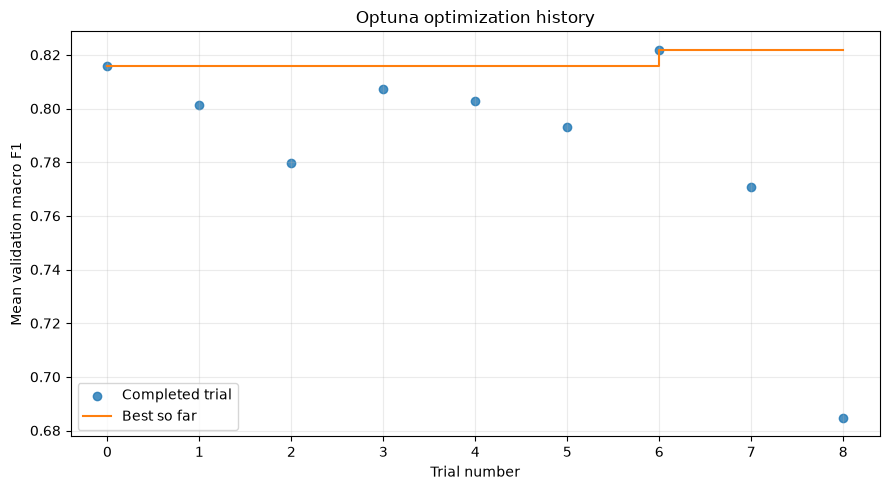

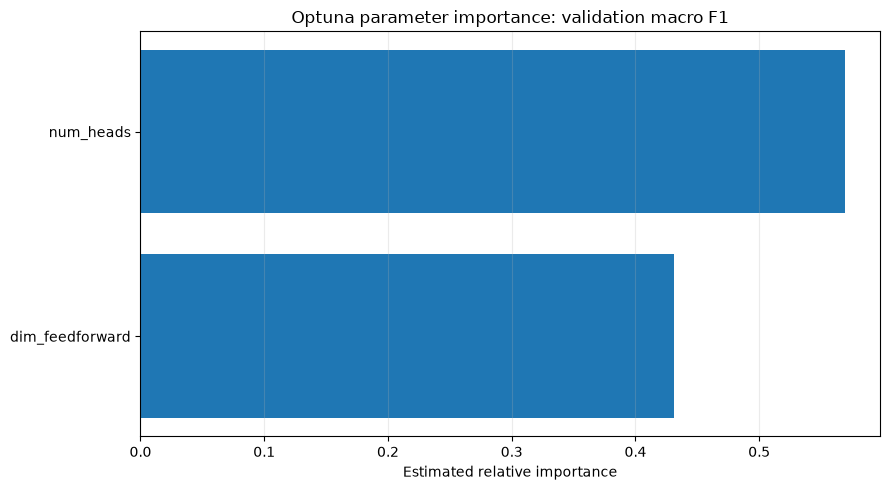

Graphs saved in: C:\Users\ESHAAN\BYTE\Applied-Task\Magi\FINETUNING-EXPERMENTS\NarrationImbalanceTrainingPaddedBox\runs\optuna_architecture\plots


In [5]:
# Cell purpose: Plot completed Optuna trials without starting or repeating training.
# Inputs: The in-memory study, or the saved SQLite study under runs/optuna_tuning.
# Outputs: Inline graphs and PNG files in the study's plots folder.

from pathlib import Path
import numpy as np
import matplotlib.pyplot as plt
import optuna
from config import CONFIG

# This cell can run by itself after a study has been saved.
plot_output = Path(globals().get('OUTPUT', CONFIG['run_dir'] / 'optuna_architecture'))
plot_study_name = globals().get('STUDY_NAME', 'fixed_split_architecture_v1')
plot_study = globals().get('study')
plot_database = plot_output / 'study.db'
if plot_study is None and plot_database.exists():
    plot_study = optuna.load_study(
        study_name=plot_study_name,
        storage='sqlite:///' + plot_database.resolve().as_posix(),
    )

completed = [] if plot_study is None else [
    trial for trial in plot_study.trials
    if trial.state == optuna.trial.TrialState.COMPLETE
    and trial.value is not None and np.isfinite(trial.value)
]
if not completed:
    print('No completed Optuna trials yet. Run the tuning cell, then rerun this plotting cell.')
else:
    plots = plot_output / 'plots'
    plots.mkdir(parents=True, exist_ok=True)
    trial_numbers = [trial.number for trial in completed]
    scores = np.array([trial.value for trial in completed])

    # Each dot is the mean validation macro F1 across the fixed search seeds.
    # The line shows the highest score found up to that trial.
    fig, ax = plt.subplots(figsize=(9, 5))
    ax.scatter(trial_numbers, scores, label='Completed trial', alpha=0.8)
    ax.step(trial_numbers, np.maximum.accumulate(scores), where='post',
            color='tab:orange', label='Best so far')
    ax.set(xlabel='Trial number', ylabel='Mean validation macro F1',
           title='Optuna optimization history')
    ax.grid(alpha=0.25)
    ax.legend()
    fig.tight_layout()
    fig.savefig(plots / 'optimization_history.png', dpi=160, bbox_inches='tight')
    plt.show()
    plt.close(fig)

    # Importance estimates need multiple trials and changing parameter values.
    # They describe this search on this validation split, not causal effects.
    varying_parameters = [
        name for name in completed[0].params
        if all(name in trial.params for trial in completed)
        and len({trial.params[name] for trial in completed}) > 1
    ]
    if len(completed) >= 2 and varying_parameters:
        try:
            importance = optuna.importance.get_param_importances(
                plot_study,
                evaluator=optuna.importance.FanovaImportanceEvaluator(seed=42),
                params=varying_parameters,
            )
        except (ValueError, RuntimeError) as error:
            print('Parameter importance is not available for these trials:', error)
        else:
            names = list(reversed(importance))
            fig, ax = plt.subplots(figsize=(9, 5))
            ax.barh(names, [importance[name] for name in names])
            ax.set(xlabel='Estimated relative importance',
                   title='Optuna parameter importance: validation macro F1')
            ax.grid(axis='x', alpha=0.25)
            fig.tight_layout()
            fig.savefig(plots / 'parameter_importance.png', dpi=160, bbox_inches='tight')
            plt.show()
            plt.close(fig)
    else:
        print('Parameter importance needs at least two completed trials with changing parameters.')
    print('Graphs saved in:', plots)


Run this stage using this experiment's configuration and caches.


## Export BestParamTuning
Run this cell after search or after the five-seed report. It can also run independently. It compares completed candidates from notebooks 08 and 09 by their three-seed mean macro F1 (requiring the same split and seeds), then exports the winning candidate's highest-scoring available seed checkpoint. Run again after notebook 09 finishes to refresh the overall winner. No training runs here.


In [6]:
# Cell purpose: Export the overall best completed tuning candidate and study metadata.
# Inputs: Saved studies and completed seed checkpoints from notebooks 08 and 09.
# Outputs: BestParamTuning/best.pt, model.py, parameter/metadata JSON and study snapshots.
# No training is run. Rerunning refreshes the export using the available completed studies.
from config import CONFIG
from export_best_tuning import export_best_tuning

best_export = export_best_tuning(CONFIG['run_dir'].parent)


Exported: C:\Users\ESHAAN\BYTE\Applied-Task\Magi\FINETUNING-EXPERMENTS\NarrationImbalanceTrainingPaddedBox\BestParamTuning
Winning study: fixed_split_architecture_v1 | trial: 6 | mean macro F1: 0.8219019308229694
Checkpoint seed: 99 | validation macro F1: 0.8501006036217305
